# Evaluación Final de Estadística

### **Preparación: importar librerías y cargar los datos**

Usamos pandas para tablas y medidas, matplotlib y seaborn para los gráficos, statsmodels para las regresiones lineales y scikit-learn para las regresiones logísticas, igual que en los ejercicios de clase.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import display

# Mostrar números con cuatro decimales en las tablas
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_style('whitegrid')

In [2]:
#4 Cargar los datos directamente desde Seaborn
df = sns.load_dataset('tips')

print('Dimensiones del dataset:', df.shape)
print('Primeras cinco filas:')
display(df.head())

Dimensiones del dataset: (244, 7)
Primeras cinco filas:


,total_bill,tip,sex,smoker,day,time,size
0,16.9900,1.0100,Female,No,Sun,Dinner,2
1,10.3400,1.6600,Male,No,Sun,Dinner,3
2,21.0100,3.5000,Male,No,Sun,Dinner,3
3,23.6800,3.3100,Male,No,Sun,Dinner,2
4,24.5900,3.6100,Female,No,Sun,Dinner,4


In [3]:
#5 Revisar los tipos de datos y la presencia de valores faltantes
print('Tipos de datos:')
print(df.dtypes)
print('\nValores faltantes por columna:')
print(df.isnull().sum())
print('\nRegistros idénticos:', df.duplicated().sum())

# Resumen general de las variables numéricas
display(df.describe())

Tipos de datos:
total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object

Valores faltantes por columna:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Registros idénticos: 1


,total_bill,tip,size
count,244.0000,244.0000,244.0000
mean,19.7859,2.9983,2.5697
std,8.9024,1.3836,0.9511
min,3.0700,1.0000,1.0000
25%,13.3475,2.0000,2.0000
50%,17.7950,2.9000,2.0000
75%,24.1275,3.5625,3.0000
max,50.8100,10.0000,6.0000


Decisión sobre la limpieza: el dataset contiene 244 observaciones y no presenta valores faltantes. Se detecta un par de filas idénticas, pero se conserva porque dos cuentas pueden tener los mismos valores sin que necesariamente se trate de un error de registro. Así se evita alterar el conjunto original sin una justificación suficiente.

## 1. Estadística descriptiva
### 1.1 Media, mediana, varianza y desviación estándar
Las medidas se calculan por separado para total_bill y tip. pandas calcula la varianza y desviación estándar muestrales por defecto (dividiendo entre n − 1), de manera consistente con los ejercicios de clase.

In [4]:
#8 Cálculos de tendencia central y dispersión
variables = ['total_bill', 'tip']

medidas = pd.DataFrame({
    'Media': df[variables].mean(),
    'Mediana': df[variables].median(),
    'Varianza': df[variables].var(),
    'Desv. estándar': df[variables].std()
})

display(medidas.round(4))

,Media,Mediana,Varianza,Desv. estándar
total_bill,19.7859,17.7950,79.2529,8.9024
tip,2.9983,2.9000,1.9145,1.3836


**Interpretación:**
- Cuenta (total_bill): la media es 19.7859 y la mediana es 17.7950. Como la media supera a la mediana, es posible que algunas cuentas de montos altos estén elevando el promedio. La varianza es 79.2529 y la desviación estándar es 8.9024 unidades monetarias.
- Propina (tip): la media es 2.9983 y la mediana es 2.9000. La varianza es 1.9145 y la desviación estándar es 1.3836 unidades monetarias. Las propinas tienden a variar menos en términos absolutos que los importes de las cuentas.
La varianza está expresada en unidades monetarias al cuadrado; la desviación estándar se expresa en las mismas unidades que la variable.

### 1.2 Cuantiles de total_bill
Se calculan los cuantiles 0.25, 0.50 y 0.75, que corresponden al primer cuartil, la mediana y el tercer cuartil.

In [5]:
#11 Cuantiles y rango intercuartílico
cuantiles = df['total_bill'].quantile([0.25, 0.50, 0.75])
cuantiles.index = ['Q1 (25 %)', 'Q2 (50 %)', 'Q3 (75 %)']
print('Cuantiles de total_bill:')
display(cuantiles.to_frame(name='Valor').round(4))

rango_intercuartilico = cuantiles.loc['Q3 (75 %)'] - cuantiles.loc['Q1 (25 %)']
print(f'Rango intercuartílico (RIC): {rango_intercuartilico:.4f}')

Cuantiles de total_bill:


,Valor
Q1 (25 %),13.3475
Q2 (50 %),17.7950
Q3 (75 %),24.1275


Rango intercuartílico (RIC): 10.7800


**Interpretación:** aproximadamente el 25 % de las cuentas tiene un importe de 13.3475 o menos, el 50 % se sitúa en 17.7950 o menos y el 75 % corresponde a cuentas de 24.1275 o menos. El rango intercuartílico es 10.7800, lo cual indica la amplitud de los importes del 50 % central de las cuentas.

### 1.3 Histograma de total_bill
El histograma permite observar cómo se distribuyen los montos de las cuentas. Se realiza con matplotlib, como en el cuaderno de gráficos estadísticos.

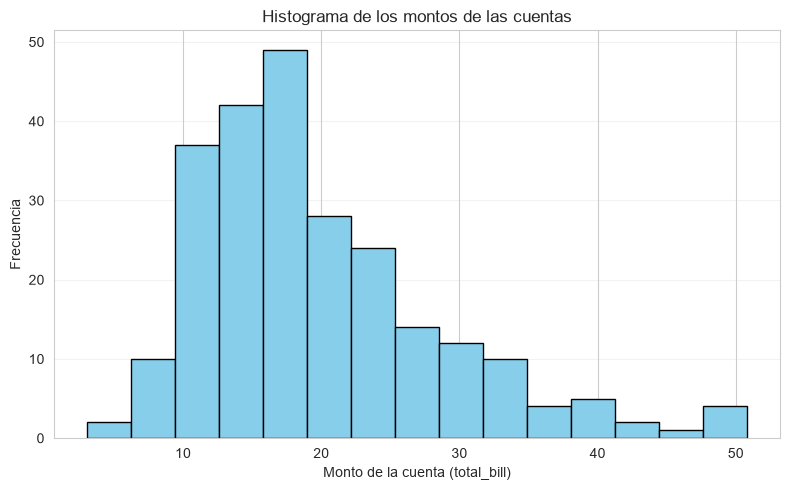

In [6]:
#14 Histograma de los montos de las cuentas
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(df['total_bill'], bins=15, edgecolor='black', color='skyblue')
ax.set_title('Histograma de los montos de las cuentas')
ax.set_xlabel('Monto de la cuenta (total_bill)')
ax.set_ylabel('Frecuencia')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretación del histograma:** la mayor concentración de cuentas se encuentra en los montos bajos e intermedios. Se observa una cola hacia la derecha, pues existen algunas cuentas relativamente altas, pero son menos frecuentes. Esta asimetría positiva es coherente con que la media (19.7859) sea mayor que la mediana (17.7950).

### 1.4 Boxplot de tip según sex
El diagrama de caja permite comparar la mediana, la dispersión y los posibles valores atípicos de las propinas entre las categorías de sex. Se utiliza sns.boxplot(), igual que en clase.

,count,mean,median,std
sex,,,,
Male,157,3.0896,3.0000,1.4891
Female,87,2.8334,2.7500,1.1595


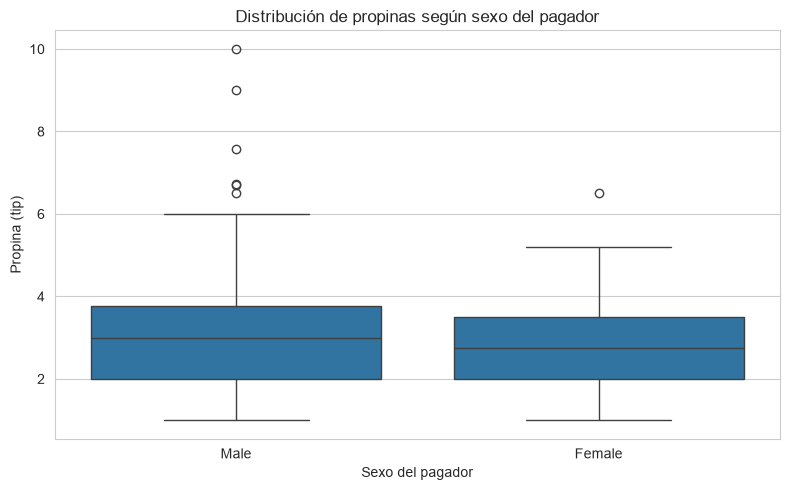

In [7]:
#17 Resumen por sexo para apoyar la interpretación del gráfico
resumen_sexo = df.groupby('sex', observed=True)['tip'].agg(['count', 'mean', 'median', 'std'])
display(resumen_sexo.round(4))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='sex', y='tip', order=['Male', 'Female'])
plt.title('Distribución de propinas según sexo del pagador')
plt.xlabel('Sexo del pagador')
plt.ylabel('Propina (tip)')
plt.tight_layout()
plt.show()

**Interpretación del boxplot:** la mediana de propina para Male es 3.00, mientras que para Female es 2.75. La dispersión y la presencia de valores atípicos también pueden observarse en el gráfico. Por ejemplo, en el grupo Male aparecen propinas especialmente altas. Esta comparación es descriptiva: no permite afirmar que el sexo cause diferencias en las propinas, porque intervienen otros factores como el monto de la cuenta y el tamaño del grupo.

## 2. Correlación y regresión lineal
### 2.1 Correlación de Pearson
El coeficiente de Pearson mide la dirección y la intensidad de la relación lineal entre dos variables cuantitativas. Se calcula entre total_bill y tip con .corr(), tal como se trabajó en clase.

In [8]:
#20 Coeficiente de correlación de Pearson
correlacion = df['total_bill'].corr(df['tip'])
print(f'Coeficiente de Pearson entre total_bill y tip: {correlacion:.4f}')

Coeficiente de Pearson entre total_bill y tip: 0.6757


**Interpretación:** se obtiene r = 0.6757, lo que indica una correlación lineal positiva moderadamente fuerte. En general, cuando aumenta total_bill, también tiende a aumentar tip. La correlación no demuestra por sí sola una relación de causa y efecto.

### 2.2 Gráfico de dispersión y tendencia lineal
Se utiliza sns.regplot() para visualizar la relación, siguiendo el ejemplo de regresión lineal de clase.

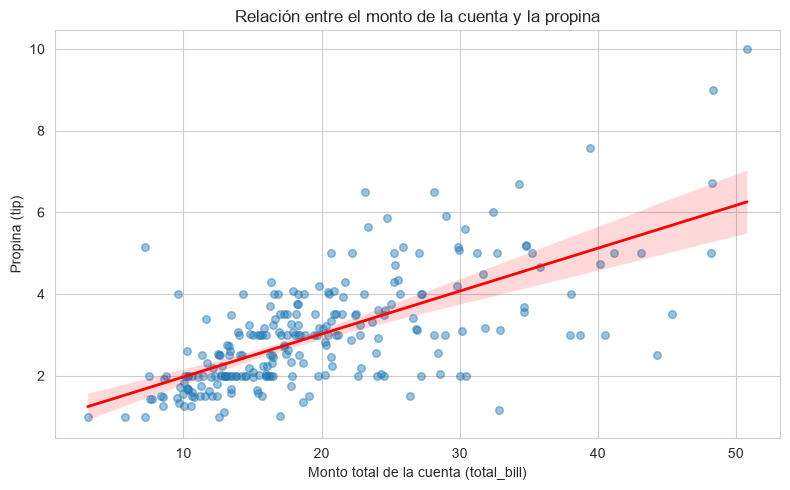

In [9]:
#23 Diagrama de dispersión con línea de regresión
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df,
    x='total_bill',
    y='tip',
    scatter_kws={'alpha': 0.45, 's': 30},
    line_kws={'color': 'red', 'linewidth': 2}
)
plt.title('Relación entre el monto de la cuenta y la propina')
plt.xlabel('Monto total de la cuenta (total_bill)')
plt.ylabel('Propina (tip)')
plt.tight_layout()
plt.show()

**Interpretación del gráfico:** se observa una tendencia ascendente: los montos de cuenta mayores suelen estar acompañados de propinas mayores. Sin embargo, los puntos no están exactamente sobre la recta, por lo que hay variación de las propinas que el monto total de la cuenta no explica.

### 2.3 Regresión lineal simple
Se modela tip como variable dependiente (Y) y total_bill como variable independiente (X). Como en clase, se agrega la constante con sm.add_constant() y se ajusta el modelo con sm.OLS(...).fit().

In [10]:
#26 Variables para regresión lineal simple
X_simple = df[['total_bill']]
X_simple = sm.add_constant(X_simple)
y_lineal = df['tip']

# Ajustar el modelo de mínimos cuadrados ordinarios
modelo_simple = sm.OLS(y_lineal, X_simple).fit()
print(modelo_simple.summary())

                            OLS Regression Results                            
Dep. Variable:                    tip   R-squared:                       0.457
Model:                            OLS   Adj. R-squared:                  0.454
Method:                 Least Squares   F-statistic:                     203.4
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           6.69e-34
Time:                        11:41:15   Log-Likelihood:                -350.54
No. Observations:                 244   AIC:                             705.1
Df Residuals:                     242   BIC:                             712.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9203      0.160      5.761      0.0

In [11]:
#27 Presentar por separado los coeficientes y el R²
print('Coeficientes del modelo simple:')
display(modelo_simple.params.to_frame('Coeficiente').round(4))
print(f'R²: {modelo_simple.rsquared:.4f}')
print(f'R² ajustado: {modelo_simple.rsquared_adj:.4f}')
print(f'Ecuación: tip = {modelo_simple.params["const"]:.4f} + '
      f'{modelo_simple.params["total_bill"]:.4f} * total_bill')

Coeficientes del modelo simple:


,Coeficiente
const,0.9203
total_bill,0.1050


R²: 0.4566
R² ajustado: 0.4544
Ecuación: tip = 0.9203 + 0.1050 * total_bill


**Interpretación:**
El coeficiente de total_bill es 0.1050: por cada unidad monetaria adicional en la cuenta, el modelo estima una propina promedio aproximadamente 0.1050 unidades mayor. El intercepto 0.9203 es la predicción teórica para una cuenta de cero, aunque no debe tomarse como una situación real de interés. El R² = 0.4566 indica que el monto de la cuenta explica alrededor del 45.66 % de la variación de las propinas dentro de esta muestra.

### 2.4 Regresión lineal múltiple
Ahora se agrega size como segunda variable independiente, para comprobar si el tamaño del grupo contribuye a explicar la propina una vez considerado total_bill.

In [12]:
#30 Modelo lineal múltiple con dos predictores
X_multiple = df[['total_bill', 'size']]
X_multiple = sm.add_constant(X_multiple)

modelo_multiple = sm.OLS(y_lineal, X_multiple).fit()
print(modelo_multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                    tip   R-squared:                       0.468
Model:                            OLS   Adj. R-squared:                  0.463
Method:                 Least Squares   F-statistic:                     105.9
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           9.67e-34
Time:                        11:41:15   Log-Likelihood:                -347.99
No. Observations:                 244   AIC:                             702.0
Df Residuals:                     241   BIC:                             712.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6689      0.194      3.455      0.0

In [13]:
#31 Comparación de la bondad de ajuste
comparacion_lineal = pd.DataFrame({
    'Modelo': ['Lineal simple', 'Lineal múltiple'],
    'R²': [modelo_simple.rsquared, modelo_multiple.rsquared],
    'R² ajustado': [modelo_simple.rsquared_adj, modelo_multiple.rsquared_adj]
})
display(comparacion_lineal.round(4))

print('Coeficientes del modelo múltiple:')
display(pd.DataFrame({
    'Coeficiente': modelo_multiple.params,
    'Valor p': modelo_multiple.pvalues
}).round(4))

print(f'Ecuación: tip = {modelo_multiple.params["const"]:.4f} + '
      f'{modelo_multiple.params["total_bill"]:.4f} * total_bill + '
      f'{modelo_multiple.params["size"]:.4f} * size')

,Modelo,R²,R² ajustado
0,Lineal simple,0.4566,0.4544
1,Lineal múltiple,0.4679,0.4635


Coeficientes del modelo múltiple:


,Coeficiente,Valor p
const,0.6689,0.0006
total_bill,0.0927,0.0000
size,0.1926,0.0249


Ecuación: tip = 0.6689 + 0.0927 * total_bill + 0.1926 * size


**Interpretación:**

- total_bill (0.0927): manteniendo fijo el tamaño del grupo, una unidad monetaria más en la cuenta se asocia con aproximadamente 0.0927 unidades más de propina estimada.
- size (0.1926): manteniendo fijo el importe de la cuenta, cada persona adicional se asocia con aproximadamente 0.1926 unidades más de propina estimada. Su valor p es cercano a 0.0249 dentro de este modelo.
- Comparación: el R² ajustado pasa de 0.4544 en el modelo simple a 0.4635 en el múltiple. Es una mejora pequeña (aproximadamente 0.0091), por lo que size sí aporta información adicional, pero el monto total sigue siendo el predictor más importante entre los dos.
Estas asociaciones no prueban causalidad y su interpretación se limita a las relaciones presentes en los datos.

## 3. Correlación y regresión logística
### 3.1 Crear tip_alto y codificar smoker
El problema pide definir tip_alto con valor 1 si tip es estrictamente mayor que su mediana y 0 en caso contrario. También se codifica smoker como No = 0 y Yes = 1. Se usa una copia de las variables para no alterar los valores originales.

In [14]:
#34 Variable binaria de la propina
mediana_tip = df['tip'].median()
df['tip_alto'] = (df['tip'] > mediana_tip).astype(int)

# Codificar smoker en 0 y 1
df['smoker_bin'] = df['smoker'].map({'No': 0, 'Yes': 1}).astype(int)

print(f'Mediana usada como referencia: {mediana_tip:.4f}')
print('Frecuencias de tip_alto (0 y 1):')
print(df['tip_alto'].value_counts().sort_index())
print('\nCodificación de smoker:')
display(pd.crosstab(df['smoker'], df['smoker_bin']))
print('\nEjemplo de las nuevas columnas:')
display(df[['tip', 'tip_alto', 'smoker', 'smoker_bin']].head())

Mediana usada como referencia: 2.9000
Frecuencias de tip_alto (0 y 1):
tip_alto
0    122
1    122
Name: count, dtype: int64

Codificación de smoker:


smoker_bin,0,1
smoker,,
Yes,0,93
No,151,0



Ejemplo de las nuevas columnas:


,tip,tip_alto,smoker,smoker_bin
0,1.0100,0,No,0
1,1.6600,0,No,0
2,3.5000,1,No,0
3,3.3100,1,No,0
4,3.6100,1,No,0


**Interpretación:** como la mediana es 2.90, las propinas mayores que 2.90 se clasifican como altas (1) y las propinas iguales o menores que 2.90 como no altas (0). Hay 122 casos en cada categoría. La variable smoker_bin distingue a quienes están registrados como fumadores (1) de quienes no (0).

### 3.2 Regresión logística simple
Se ajusta un modelo LogisticRegression de scikit-learn, siguiendo el procedimiento de la clase de regresión logística. La variable dependiente es tip_alto y el único predictor es total_bill.

El odds ratio (OR) se obtiene elevando e al coeficiente: np.exp(coeficiente). Si OR es mayor que 1, las odds del evento aumentan; si es menor que 1, disminuyen. Odds y probabilidad no son lo mismo.

In [15]:
#37 Regresión logística simple
X_log_simple = df[['total_bill']]
y_logistica = df['tip_alto']

logistica_simple = LogisticRegression(max_iter=1000)
logistica_simple.fit(X_log_simple, y_logistica)

coef_log_simple = pd.DataFrame({
    'Variable': X_log_simple.columns,
    'Coeficiente': logistica_simple.coef_[0],
    'Odds ratio': np.exp(logistica_simple.coef_[0])
})
print(f'Intercepto: {logistica_simple.intercept_[0]:.4f}')
display(coef_log_simple.round(4))

Intercepto: -3.6866


,Variable,Coeficiente,Odds ratio
0,total_bill,0.1960,1.2165


**Interpretación del OR:** el coeficiente de total_bill es aproximadamente 0.1960, con un odds ratio de 1.2165. Por cada unidad monetaria adicional en la cuenta, las odds de tener una propina por encima de 2.90 se multiplican por aproximadamente 1.2165, es decir, aumentan alrededor de 21.65 %. Esto no significa que la probabilidad suba 21.65 puntos porcentuales.

### 3.3 Regresión logística múltiple
Se añaden las variables size y smoker_bin como predictores, conservando total_bill. Los odds ratios se interpretan manteniendo constantes las demás variables.

In [16]:
#40 Regresión logística con tres predictores
X_log_multiple = df[['total_bill', 'size', 'smoker_bin']]

logistica_multiple = LogisticRegression(max_iter=1000)
logistica_multiple.fit(X_log_multiple, y_logistica)

coef_log_multiple = pd.DataFrame({
    'Variable': X_log_multiple.columns,
    'Coeficiente': logistica_multiple.coef_[0],
    'Odds ratio': np.exp(logistica_multiple.coef_[0])
})
print(f'Intercepto: {logistica_multiple.intercept_[0]:.4f}')
display(coef_log_multiple.round(4))

Intercepto: -4.0224


,Variable,Coeficiente,Odds ratio
0,total_bill,0.1794,1.1965
1,size,0.2382,1.2690
2,smoker_bin,0.1475,1.1590


**Interpretación de los OR del modelo múltiple:**
- total_bill: OR ≈ 1.1965. Manteniendo constantes size y smoker_bin, cada unidad adicional de cuenta se asocia con un incremento de aproximadamente 19.65 % en las odds de una propina alta.
- size: OR ≈ 1.2690. Manteniendo constantes los demás predictores, una persona adicional se asocia con un incremento estimado de 26.90 % en las odds de una propina alta.
- smoker_bin: OR ≈ 1.1590. A igual monto de cuenta y tamaño del grupo, las odds estimadas de propina alta entre los registros de fumadores son aproximadamente 15.90 % mayores que las de no fumadores.

Estas cifras representan asociaciones estimadas, no efectos causales. Además, un OR superior a 1 no demuestra por sí solo que la asociación sea estadísticamente significativa.

### 3.4 Evaluación de los modelos logísticos con datos de prueba
En el cuaderno de clase se utilizó train_test_split para dividir los datos en 80 % entrenamiento y 20 % prueba, y se evaluó el resultado mediante exactitud (accuracy) y matriz de confusión. Repetimos ese procedimiento para comparar el modelo simple y el múltiple con las mismas observaciones de prueba. Esta evaluación es independiente del ajuste sobre la muestra completa realizado arriba para interpretar los coeficientes.

In [17]:
#43 Usar los mismos registros de entrenamiento y prueba en ambos modelos
indices_train, indices_test = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=df['tip_alto']
)

resultados_prueba = []
for nombre, columnas in [
    ('Logístico simple', ['total_bill']),
    ('Logístico múltiple', ['total_bill', 'size', 'smoker_bin'])
]:
    X_train = df.loc[indices_train, columnas]
    X_test = df.loc[indices_test, columnas]
    y_train = df.loc[indices_train, 'tip_alto']
    y_test = df.loc[indices_test, 'tip_alto']

    modelo_prueba = LogisticRegression(max_iter=1000)
    modelo_prueba.fit(X_train, y_train)
    predicciones = modelo_prueba.predict(X_test)

    exactitud = accuracy_score(y_test, predicciones)
    matriz = confusion_matrix(y_test, predicciones)
    resultados_prueba.append({'Modelo': nombre, 'Exactitud en prueba': exactitud})

    print(f'--- {nombre} ---')
    print(f'Exactitud: {exactitud:.4f}')
    print('Matriz de confusión (filas: reales; columnas: predichos):')
    print(matriz)
    print()

display(pd.DataFrame(resultados_prueba).round(4))

--- Logístico simple ---
Exactitud: 0.6939
Matriz de confusión (filas: reales; columnas: predichos):
[[20  5]
 [10 14]]

--- Logístico múltiple ---
Exactitud: 0.7143
Matriz de confusión (filas: reales; columnas: predichos):
[[20  5]
 [ 9 15]]



,Modelo,Exactitud en prueba
0,Logístico simple,0.6939
1,Logístico múltiple,0.7143


**Interpretación de la evaluación:** con esta división, el modelo logístico simple logra una exactitud aproximada de 69.39 %, y el múltiple logra 71.43 %. El modelo múltiple acierta ligeramente más en los registros de prueba, pero la diferencia es pequeña y se basa únicamente en esta partición. La matriz de confusión permite identificar aciertos y errores para ambas clases (tip_alto = 0 y 1). No se debe asumir que estas exactitudes serán iguales con nuevos clientes.

## 4. Interpretación final
En el dataset tips, el monto total de la cuenta (total_bill) es la variable que presenta la relación más clara con la propina. La correlación de Pearson es positiva (r = 0.6757), y la regresión lineal simple explica aproximadamente el 45.66 % de la variación de tip. El tamaño del grupo (size) aporta información adicional, aunque la mejora del R² ajustado es pequeña (de 0.4544 a 0.4635). En la regresión logística, un mayor monto de cuenta se asocia también con mayores odds de recibir una propina superior a la mediana; size y smoker_bin muestran asociaciones estimadas positivas, pero esto no basta para establecer causalidad ni significación estadística. Entre las limitaciones se encuentran el carácter observacional de los registros, los valores extremos, el tamaño de la muestra y la ausencia de factores como la calidad del servicio. Por ello, los modelos son útiles para describir asociaciones y realizar predicciones aproximadas, pero no explican por completo el comportamiento de las propinas.

### Comentario sobre el procedimiento
- El dataset se cargó directamente desde seaborn, como requiere la evaluación.
- Se aplicaron los métodos trabajados en los cuadernos de clase: estadísticas de pandas, gráficos de matplotlib y seaborn, regresión lineal con statsmodels y regresión logística con scikit-learn.
- El modelo logístico de scikit-learn utiliza regularización L2 por defecto. Por eso sus coeficientes y odds ratios pueden variar muy levemente respecto de un ajuste logístico sin regularización realizado con otro paquete.
- Las conclusiones deben leerse como asociaciones de esta muestra, no como pruebas de causalidad.